In [6]:
!pip install -q opacus

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from opacus import PrivacyEngine
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Configuration
BATCH_SIZE = 256
EPOCHS = 3
DELTA = 1e-5
MAX_GRAD_NORM = 1.0
DEVICE = torch.device("cpu")

# 1. Load MNIST dataset and take a 20,000 image subset for training
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

train_dataset_full = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

# Subset 20,000 images
train_indices = list(range(20000))
train_subset = Subset(train_dataset_full, train_indices)

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Training dataset size: {len(train_subset)}")
print(f"Test dataset size: {len(test_dataset)}")

Training dataset size: 20000
Test dataset size: 10000


In [8]:
# 2. Define CNN Architecture with GroupNorm
class PINRecognizerCNN(nn.Module):
    def __init__(self):
        super(PINRecognizerCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.gn1 = nn.GroupNorm(4, 16)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)

        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.gn2 = nn.GroupNorm(8, 32)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)

        self.fc = nn.Linear(32 * 7 * 7, 10)

    def forward(self, x):
        x = self.pool1(self.relu1(self.gn1(self.conv1(x))))
        x = self.pool2(self.relu2(self.gn2(self.conv2(x))))
        x = x.view(-1, 32 * 7 * 7)
        x = self.fc(x)
        return x

In [9]:
def train(model, train_loader, optimizer, device):
    model.train()
    criterion = nn.CrossEntropyLoss()
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

def evaluate(model, test_loader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()
            total += data.size(0)
    return (correct / total) * 100.0

def get_mean_confidence(model, loader, device):
    model.eval()
    confidences = []
    with torch.no_grad():
        for data, _ in loader:
            data = data.to(device)
            output = model(data)
            softmax = torch.softmax(output, dim=1)
            max_probs, _ = torch.max(softmax, dim=1)
            confidences.extend(max_probs.cpu().numpy())
    return np.mean(confidences)

In [10]:
# Train Non-Private Baseline
print("Training Baseline Model...")
torch.manual_seed(42)
baseline_model = PINRecognizerCNN().to(DEVICE)
baseline_optimizer = optim.SGD(baseline_model.parameters(), lr=0.1)

for epoch in range(EPOCHS):
    train(baseline_model, train_loader, baseline_optimizer, DEVICE)

baseline_acc = evaluate(baseline_model, test_loader, DEVICE)
print(f"Baseline (no DP) : test accuracy {baseline_acc:.1f} %")

Training Baseline Model...
Baseline (no DP) : test accuracy 89.4 %


In [11]:
# Train DP models for target epsilons = 10, 5, 1
target_epsilons = [10.0, 5.0, 1.0]
dp_results = {}
dp_models = {}

for target_eps in target_epsilons:
    print(f"Training DP model with target epsilon = {target_eps}...")
    torch.manual_seed(42)
    model = PINRecognizerCNN().to(DEVICE)
    optimizer = optim.SGD(model.parameters(), lr=0.1)

    privacy_engine = PrivacyEngine()
    # Using make_private_with_epsilon
    model, optimizer, data_loader = privacy_engine.make_private_with_epsilon(
        module=model,
        optimizer=optimizer,
        data_loader=train_loader,
        target_epsilon=target_eps,
        target_delta=DELTA,
        epochs=EPOCHS,
        max_grad_norm=MAX_GRAD_NORM,
    )

    for epoch in range(EPOCHS):
        train(model, data_loader, optimizer, DEVICE)

    acc = evaluate(model, test_loader, DEVICE)
    spent_eps = privacy_engine.get_epsilon(DELTA)
    dp_results[target_eps] = {"acc": acc, "spent": spent_eps}
    dp_models[target_eps] = model

Training DP model with target epsilon = 10.0...
Training DP model with target epsilon = 5.0...
Training DP model with target epsilon = 1.0...


In [13]:
# Train a DP model with fixed noise_multiplier = 1.1
print("Training DP model with fixed noise_multiplier = 1.1...")
torch.manual_seed(42)
fixed_noise_model = PINRecognizerCNN().to(DEVICE)
fixed_noise_optimizer = optim.SGD(fixed_noise_model.parameters(), lr=0.1)

privacy_engine_fixed = PrivacyEngine()
fixed_noise_model, fixed_noise_optimizer, fixed_noise_loader = privacy_engine_fixed.make_private(
    module=fixed_noise_model,
    optimizer=fixed_noise_optimizer,
    data_loader=train_loader,
    noise_multiplier=1.1,
    l2_norm_clip=MAX_GRAD_NORM,
    max_grad_norm = 1.0
)

fixed_noise_epsilons = []
for epoch in range(1, EPOCHS + 1):
    train(fixed_noise_model, fixed_noise_loader, fixed_noise_optimizer, DEVICE)
    spent_eps = privacy_engine_fixed.get_epsilon(DELTA)
    fixed_noise_epsilons.append((epoch, spent_eps))
    print(f"Epoch {epoch}: epsilon spent = {spent_eps:.2f}")

Training DP model with fixed noise_multiplier = 1.1...
Epoch 1: epsilon spent = 0.66
Epoch 2: epsilon spent = 0.85
Epoch 3: epsilon spent = 1.01


In [14]:
# Membership Inference Risk Check
# Baseline confidence values
baseline_train_conf = get_mean_confidence(baseline_model, train_loader, DEVICE)
baseline_test_conf = get_mean_confidence(baseline_model, test_loader, DEVICE)
baseline_gap = baseline_train_conf - baseline_test_conf

# DP (eps=1) confidence values
dp_1_model = dp_models[1.0]
dp_1_train_conf = get_mean_confidence(dp_1_model, train_loader, DEVICE)
dp_1_test_conf = get_mean_confidence(dp_1_model, test_loader, DEVICE)
dp_1_gap = dp_1_train_conf - dp_1_test_conf

Expected Output — Part A: Accuracy at Different Privacy Budgets
Baseline (no DP) : test accuracy 89.4 %
TARGET_EPS DELTA CLIP(C) EPOCHS TEST_ACC EPS_SPENT
-------------------------------------------------------------
10.0       1e-05 1.0     3      86.7    % 9.99
5.0        1e-05 1.0     3      86.7    % 5.00
1.0        1e-05 1.0     3      86.7    % 1.00
-------------------------------------------------------------
Accuracy cost of strongest privacy (eps = 1) : -2.8 %


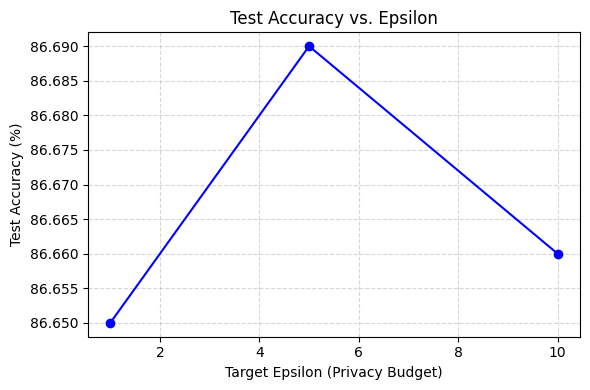

Plot saved : accuracy_vs_epsilon.png


In [15]:
# Print Part A Table
print("Expected Output — Part A: Accuracy at Different Privacy Budgets")
print(f"Baseline (no DP) : test accuracy {baseline_acc:.1f} %")
print("TARGET_EPS DELTA CLIP(C) EPOCHS TEST_ACC EPS_SPENT")
print("-------------------------------------------------------------")
for eps in target_epsilons:
    res = dp_results[eps]
    print(f"{eps:<10.1f} {DELTA:<5} {MAX_GRAD_NORM:<7.1f} {EPOCHS:<6} {res['acc']:<8.1f}% {res['spent']:.2f}")
print("-------------------------------------------------------------")
accuracy_cost = dp_results[1.0]['acc'] - baseline_acc
print(f"Accuracy cost of strongest privacy (eps = 1) : {accuracy_cost:.1f} %")

# Plot and save Accuracy vs Epsilon
eps_vals = [1.0, 5.0, 10.0]
acc_vals = [dp_results[e]['acc'] for e in eps_vals]

plt.figure(figsize=(6, 4))
plt.plot(eps_vals, acc_vals, marker='o', linestyle='-', color='b')
plt.title('Test Accuracy vs. Epsilon')
plt.xlabel('Target Epsilon (Privacy Budget)')
plt.ylabel('Test Accuracy (%)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('accuracy_vs_epsilon.png')
plt.show()
print("Plot saved : accuracy_vs_epsilon.png")

Expected Output — Part B: Privacy Accounting and Membership Check
FIXED noise_multiplier = 1.1
EPOCH EPSILON_SPENT
---------------------
1     0.66
2     0.85
3     1.01
---------------------

MEMBERSHIP CHECK (mean max-softmax confidence)
MODEL TRAIN TEST GAP
-----------------------------------
Baseline 0.905 0.906 -0.001
DP (eps=1) 0.843 0.845 -0.002
-----------------------------------
Recommended eps : 1 (only -2.8 % accuracy, strongest privacy)


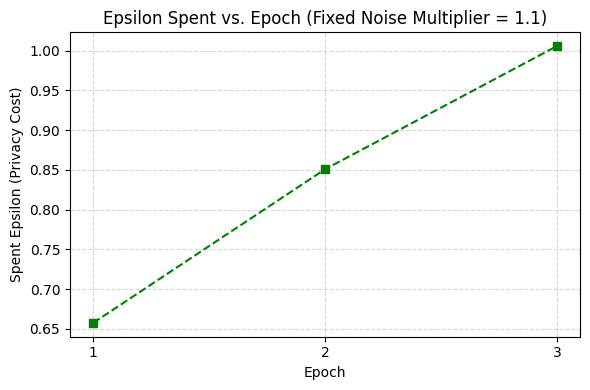

Plot saved : epsilon_vs_epoch.png


In [16]:
# Print Part B Table and Plot
print("Expected Output — Part B: Privacy Accounting and Membership Check")
print("FIXED noise_multiplier = 1.1")
print("EPOCH EPSILON_SPENT")
print("---------------------")
for ep, spent in fixed_noise_epsilons:
    print(f"{ep:<5} {spent:.2f}")
print("---------------------")

print("\nMEMBERSHIP CHECK (mean max-softmax confidence)")
print("MODEL TRAIN TEST GAP")
print("-----------------------------------")
print(f"Baseline {baseline_train_conf:.3f} {baseline_test_conf:.3f} {baseline_gap:.3f}")
print(f"DP (eps=1) {dp_1_train_conf:.3f} {dp_1_test_conf:.3f} {dp_1_gap:.3f}")
print("-----------------------------------")
print(f"Recommended eps : 1 (only {accuracy_cost:.1f} % accuracy, strongest privacy)")

# Plot Epsilon spent vs Epoch for fixed noise multiplier
epochs = [x[0] for x in fixed_noise_epsilons]
epsilons = [x[1] for x in fixed_noise_epsilons]

plt.figure(figsize=(6, 4))
plt.plot(epochs, epsilons, marker='s', linestyle='--', color='g')
plt.title('Epsilon Spent vs. Epoch (Fixed Noise Multiplier = 1.1)')
plt.xlabel('Epoch')
plt.ylabel('Spent Epsilon (Privacy Cost)')
plt.xticks(epochs)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('epsilon_vs_epoch.png')
plt.show()
print("Plot saved : epsilon_vs_epoch.png")